# 02 · Exploratory data analysis

**Input:** `la_master_stage1.csv`, one row per local authority (361), from Stage 1.
**Main measure:** 4G **indoor-threshold** coverage (RSRP ≥ −95 dBm) from Ofcom's 2023 drive tests, measured at road level.

Sections:
1. Data quality and coverage of the drive-test sample
2. Fixing a bias in the Stage 1 gap metric
3. How Vodafone compares with EE, O2 and Three
4. Where the gaps are: rural vs urban
5. Which local authorities have the worst gaps
6. Merger simulation: VodafoneThree
7. Can OpenCelliD explain the gaps? (data quality check)
8. Validation against Ofcom Connected Nations 2025
9. Findings and next steps

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

# Colab: read from Drive. Locally: read from the working folder.
CANDIDATES = [Path('/content/drive/MyDrive/vodafone-project/data/la_master_stage1.csv'), Path('la_master_stage1.csv')]
try:
    from google.colab import drive; drive.mount('/content/drive')
except ImportError:
    pass
SRC = next(p for p in CANDIDATES if p.exists())
FIG = SRC.parent / 'figures'; FIG.mkdir(exist_ok=True)
df = pd.read_csv(SRC)
print(SRC, df.shape)

# chart style: fixed colour per operator (same in every chart)
OPC = {'Vodafone': '#2a78d6', 'EE': '#eb6834', 'O2': '#1baf7a', 'Three': '#eda100', 'VodafoneThree': '#6250d6'}
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e6e5e0', '#fcfcfb'
plt.rcParams.update({'font.family': ['Inter', 'DejaVu Sans'], 'font.size': 10, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2,
    'xtick.color': INK2, 'ytick.color': INK2, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .8,
    'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor': SURF, 'axes.facecolor': SURF,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left', 'axes.axisbelow': True})
def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=160, bbox_inches='tight'); plt.show()

la_master_stage1.csv (361, 57)


## 1. Data quality and coverage of the drive-test sample

In [2]:
cn_cols = [c for c in df.columns if c.startswith('4G_')]
df[cn_cols] = df[cn_cols].fillna(0)                    # Ofcom leaves 0% cells blank (rows sum to 100)
df['prem_density'] = df.prem_count / df.area_km2      # premises per km²
df['log_density'] = np.log10(df.prem_density)
df['nation'] = df.lad_cd.str[0].map({'E': 'England', 'S': 'Scotland', 'W': 'Wales', 'N': 'N. Ireland'})
df['has_dt'] = df.vo_gap_cov_out_share.notna()

print('LAs with drive-test metrics:', df.has_dt.sum(), 'of', len(df))
display(pd.crosstab(df.nation, df.has_dt, margins=True).rename(columns={True: 'with drive-test', False: 'without'}))
print('1 km cells per LA:', df.n_cells.describe().round(0).to_dict())
# does the sample over/under-represent rural areas?
print('Median premises/km², with vs without drive-test:',
      df.groupby('has_dt').prem_density.median().round(0).to_dict())

LAs with drive-test metrics: 160 of 361


has_dt,without,with drive-test,All
nation,,,
England,166,130,296
N. Ireland,11,0,11
Scotland,7,25,32
Wales,17,5,22
All,201,160,361


1 km cells per LA: {'count': 160.0, 'mean': 79.0, 'std': 151.0, 'min': 5.0, '25%': 19.0, '50%': 40.0, '75%': 79.0, 'max': 1588.0}
Median premises/km², with vs without drive-test: {False: 395.0, True: 229.0}


**Notes**
- Only **160 of 361** local authorities have ≥5 head-to-head 1 km cells. **Northern Ireland has none**, and Wales has only 5.
- The measured local authorities are more rural than the rest (median 229 vs 395 premises/km²), because Ofcom's vehicles drive mostly outside cities.
- The analysis below describes the *measured* local authorities, not the whole UK. This needs to go in the write-up's limitations section.

## 2. Fixing a bias in the Stage 1 gap metric

Stage 1 computed `best rival = max(EE, O2)` **in each 1 km cell**, then averaged. The maximum of two noisy estimates is biased upwards, so the gap looks bigger than it is. That's why ~99% of local authorities showed Vodafone "behind".

The fairer version compares local-authority averages: `max(mean EE, mean O2) − mean Vodafone`. We also report Vodafone vs each rival separately.

In [3]:
dt = df[df.has_dt].copy()
for k in ('out', 'in'):
    V, E, O, T = (dt[f'cov_{k}_share_{o}'] for o in ('Vodafone', 'EE', 'O2', 'Three'))
    dt[f'gap_vs_EE_{k}'] = E - V
    dt[f'gap_vs_O2_{k}'] = O - V
    dt[f'gap_{k}'] = np.maximum(E, O) - V          # fair LA-level gap (>0 = Vodafone behind)
    dt[f'best_rival_{k}'] = np.maximum(E, O)

cmp = pd.DataFrame({
    'Stage 1 (cell-max, biased)': [dt.vo_gap_cov_in_share.mean(), (dt.vo_gap_cov_in_share > 0).mean()],
    'Fair: vs best rival (LA)':   [dt.gap_in.mean(), (dt.gap_in > 0).mean()],
    'vs EE only':                 [dt.gap_vs_EE_in.mean(), (dt.gap_vs_EE_in > 0).mean()],
    'vs O2 only':                 [dt.gap_vs_O2_in.mean(), (dt.gap_vs_O2_in > 0).mean()],
}, index=['mean indoor gap', 'share of LAs Vodafone behind']).round(3)
cmp

,"Stage 1 (cell-max, biased)",Fair: vs best rival (LA),vs EE only,vs O2 only
mean indoor gap,0.094,0.045,0.022,-0.016
share of LAs Vodafone behind,0.988,0.756,0.594,0.438


## 3. How Vodafone compares with EE, O2 and Three

In [4]:
ops = ['EE', 'Vodafone', 'O2', 'Three']
summ = pd.DataFrame({o: dt[f'cov_in_share_{o}'].describe(percentiles=[.25, .5, .75]) for o in ops}).T
display(summ[['mean', '25%', '50%', '75%', 'min']].round(3))

rank = dt[[f'cov_in_share_{o}' for o in ops]].rank(axis=1, ascending=False)
rank.columns = ops
display(rank.apply(lambda s: s.value_counts()).reindex([1., 2., 3., 4.]).fillna(0).astype(int).rename_axis('rank'))

# paired test: is Vodafone different from EE / O2 across the same LAs?
for r in ('EE', 'O2'):
    w = stats.wilcoxon(dt[f'cov_in_share_{r}'], dt['cov_in_share_Vodafone'])
    print(f'Vodafone vs {r}: median diff = {np.median(dt[f"cov_in_share_{r}"] - dt.cov_in_share_Vodafone):+.3f}, Wilcoxon p = {w.pvalue:.2g}')

,mean,25%,50%,75%,min
EE,0.847,0.809,0.855,0.903,0.591
Vodafone,0.825,0.763,0.851,0.906,0.486
O2,0.809,0.732,0.833,0.903,0.397
Three,0.800,0.743,0.835,0.903,0.271


,EE,Vodafone,O2,Three
rank,,,,
1.0,70,30,29,31
2.0,29,57,41,33
3.0,34,45,46,35
4.0,27,28,44,61


Vodafone vs EE: median diff = +0.017, Wilcoxon p = 0.0013
Vodafone vs O2: median diff = -0.012, Wilcoxon p = 0.00025


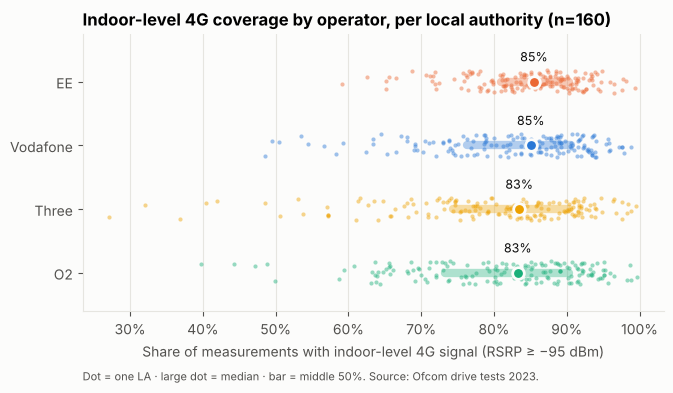

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
order = summ.sort_values('50%').index
for i, o in enumerate(order):
    v = dt[f'cov_in_share_{o}']
    q1, q2, q3 = v.quantile([.25, .5, .75])
    ax.plot([q1, q3], [i, i], color=OPC[o], lw=6, solid_capstyle='round', alpha=.35)
    ax.scatter(v, np.full(len(v), i) + np.random.default_rng(i).uniform(-.18, .18, len(v)), s=9, color=OPC[o], alpha=.45, lw=0)
    ax.scatter([q2], [i], s=70, color=OPC[o], edgecolor=SURF, lw=2, zorder=3)
    ax.text(q2, i + .32, f'{q2:.0%}', ha='center', color=INK, fontsize=9)
ax.set_yticks(range(len(order)), order); ax.grid(axis='y', visible=False); ax.set_ylim(-.6, len(order) - .25)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel('Share of measurements with indoor-level 4G signal (RSRP ≥ −95 dBm)')
ax.set_title('Indoor-level 4G coverage by operator, per local authority (n=160)')
ax.text(0, -.25, 'Dot = one LA · large dot = median · bar = middle 50%. Source: Ofcom drive tests 2023.',
        transform=ax.transAxes, color=INK2, fontsize=8)
save(fig, '01_operator_coverage')

## 4. Where the gaps are: rural vs urban

In [6]:
dt['density_band'] = pd.qcut(dt.log_density, 3, labels=['Rural (low density)', 'Mixed', 'Urban (high density)'])
band = dt.groupby('density_band', observed=True).agg(
    n=('lad_nm', 'size'),
    vodafone=('cov_in_share_Vodafone', 'mean'), ee=('cov_in_share_EE', 'mean'), o2=('cov_in_share_O2', 'mean'),
    gap=('gap_in', 'mean'), vo_notspot=('vo_notspot_in', 'mean'))
display(band.round(3))
rho, p = stats.spearmanr(dt.log_density, dt.gap_in)
print(f'Spearman(log density, fair indoor gap) = {rho:.2f}, p = {p:.2g}')

,n,vodafone,ee,o2,gap,vo_notspot
density_band,,,,,,
Rural (low density),54,0.759,0.820,0.74,0.077,0.241
Mixed,53,0.831,0.840,0.82,0.037,0.169
Urban (high density),53,0.887,0.882,0.87,0.019,0.113


Spearman(log density, fair indoor gap) = -0.42, p = 4.3e-08


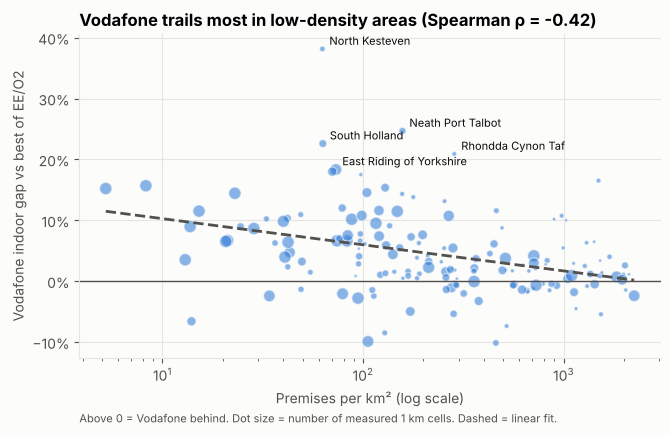

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.axhline(0, color=INK2, lw=1)
ax.scatter(dt.prem_density, dt.gap_in, s=np.clip(dt.n_cells, 8, 120) / 1.5, color=OPC['Vodafone'], alpha=.55, edgecolor=SURF, lw=1)
ax.set_xscale('log')
z = np.polyfit(dt.log_density, dt.gap_in, 1); xs = np.linspace(dt.log_density.min(), dt.log_density.max(), 50)
ax.plot(10 ** xs, np.polyval(z, xs), color=INK2, lw=2, ls='--')
for _, r in dt.nlargest(5, 'gap_in').iterrows():
    ax.annotate(r.lad_nm, (r.prem_density, r.gap_in), xytext=(5, 3), textcoords='offset points', fontsize=8, color=INK)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_xlabel('Premises per km² (log scale)'); ax.set_ylabel('Vodafone indoor gap vs best of EE/O2')
ax.set_title(f'Vodafone trails most in low-density areas (Spearman ρ = {rho:.2f})')
ax.text(0, -.2, 'Above 0 = Vodafone behind. Dot size = number of measured 1 km cells. Dashed = linear fit.',
        transform=ax.transAxes, color=INK2, fontsize=8)
save(fig, '02_gap_vs_density')

## 5. Which local authorities have the worst gaps
Only local authorities with **≥ 20 measured 1 km cells** are included, so the ranking isn't driven by a handful of cells.

,lad_nm,nation,n_cells,cov_in_share_Vodafone,cov_in_share_EE,cov_in_share_O2,gap_in,vo_notspot_in
158,North Kesteven,England,25.0,0.567,0.949,0.639,0.382,0.433
349,Neath Port Talbot,Wales,40.0,0.730,0.976,0.692,0.247,0.270
159,South Holland,England,49.0,0.592,0.818,0.708,0.226,0.408
206,Stratford-on-Avon,England,108.0,0.645,0.828,0.656,0.183,0.355
216,Malvern Hills,England,68.0,0.486,0.666,0.397,0.180,0.514
327,Argyll and Bute,Scotland,436.0,0.495,0.651,0.499,0.157,0.505
176,Cherwell,England,61.0,0.703,0.856,0.740,0.154,0.297
314,Highland,Scotland,1588.0,0.634,0.786,0.637,0.152,0.366
178,South Oxfordshire,England,77.0,0.691,0.836,0.657,0.146,0.309
317,Moray,Scotland,163.0,0.665,0.810,0.689,0.144,0.335


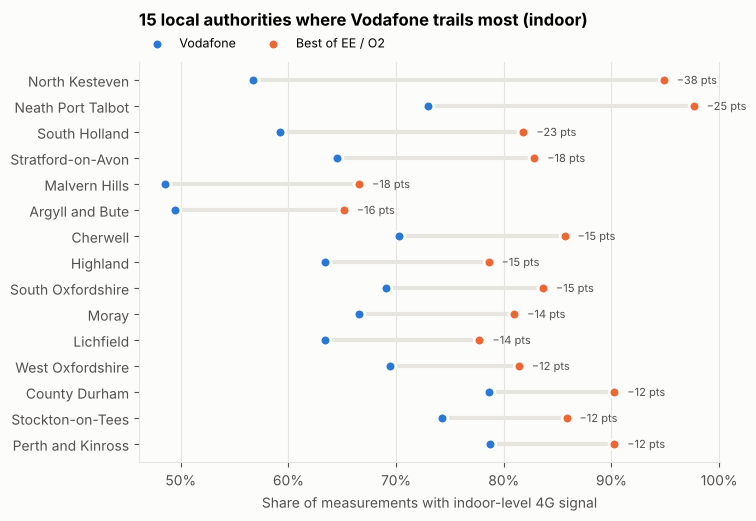

In [8]:
top = dt[dt.n_cells >= 20].nlargest(15, 'gap_in')
display(top[['lad_nm', 'nation', 'n_cells', 'cov_in_share_Vodafone', 'cov_in_share_EE', 'cov_in_share_O2', 'gap_in', 'vo_notspot_in']].round(3))

fig, ax = plt.subplots(figsize=(7.5, 5.2))
t = top.iloc[::-1]; y = np.arange(len(t))
ax.hlines(y, t.cov_in_share_Vodafone, t.best_rival_in, color=GRID, lw=3)
ax.scatter(t.cov_in_share_Vodafone, y, s=60, color=OPC['Vodafone'], edgecolor=SURF, lw=2, zorder=3, label='Vodafone')
ax.scatter(t.best_rival_in, y, s=60, color=OPC['EE'], edgecolor=SURF, lw=2, zorder=3, label='Best of EE / O2')
for yi, (_, r) in zip(y, t.iterrows()):
    ax.text(r.best_rival_in + .012, yi, f'−{r.gap_in*100:.0f} pts', va='center', fontsize=8, color=INK2)
ax.set_yticks(y, t.lad_nm); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_xlabel('Share of measurements with indoor-level 4G signal')
ax.set_title('15 local authorities where Vodafone trails most (indoor)', pad=26)
ax.legend(loc='lower left', frameon=False, ncol=2, bbox_to_anchor=(-.01, 1.0), fontsize=9)
save(fig, '03_top15_gap')

## 6. Merger simulation: VodafoneThree
`VodafoneThree` = the best of Vodafone and Three in each cell. That's a simplification: it assumes full network sharing with no spectrum changes. It's also a best-of-two measure, so we compare it with the **best of EE/O2 per cell** (also best-of-two) to keep the comparison fair.

,vodafone,vodafonethree,best_rival_cellmax,uplift_pts
density_band,,,,
Rural (low density),0.759,0.858,0.892,9.972
Mixed,0.831,0.917,0.921,8.530
Urban (high density),0.887,0.946,0.944,5.922


LAs where VodafoneThree still trails the best of EE/O2: 56%


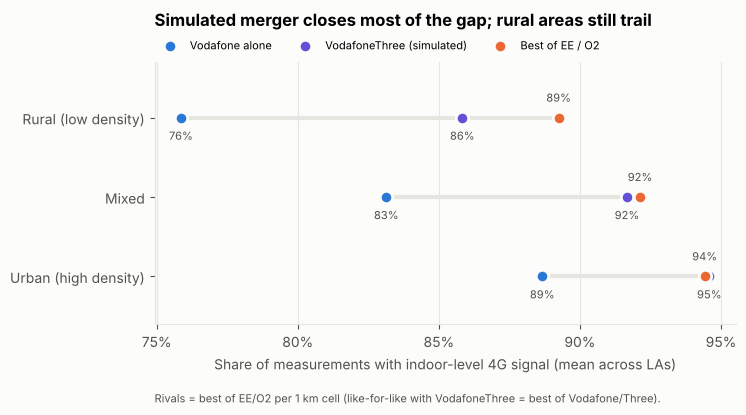

In [9]:
dt['vt_gap_in'] = dt.vo_gap_cov_in_share - (dt.cov_in_share_VodafoneThree - dt.cov_in_share_Vodafone)  # cell-best rival − VT
merge = dt.groupby('density_band', observed=True).agg(
    vodafone=('cov_in_share_Vodafone', 'mean'), vodafonethree=('cov_in_share_VodafoneThree', 'mean'),
    best_rival_cellmax=('best_rival_cov_in_share', 'mean'))
merge['uplift_pts'] = (merge.vodafonethree - merge.vodafone) * 100
display(merge.round(3))
print(f'LAs where VodafoneThree still trails the best of EE/O2: {(dt.vt_gap_in > 0).mean():.0%}')

fig, ax = plt.subplots(figsize=(7.5, 3.4))
y = np.arange(len(merge))[::-1]
ax.hlines(y, merge.vodafone, merge[['vodafonethree', 'best_rival_cellmax']].max(axis=1), color=GRID, lw=3)
for col, lab, c in [('vodafone', 'Vodafone alone', OPC['Vodafone']),
                    ('vodafonethree', 'VodafoneThree (simulated)', OPC['VodafoneThree']),
                    ('best_rival_cellmax', 'Best of EE / O2', OPC['EE'])]:
    ax.scatter(merge[col], y, s=80, color=c, edgecolor=SURF, lw=2, zorder=3, label=lab)
for yi, (_, r) in zip(y, merge.iterrows()):
    ax.text(r.vodafone, yi - .28, f'{r.vodafone:.0%}', ha='center', fontsize=8, color=INK2)
    ax.text(r.vodafonethree, yi - .28, f'{r.vodafonethree:.0%}', ha='center', fontsize=8, color=INK2)
    ax.text(r.best_rival_cellmax, yi + .2, f'{r.best_rival_cellmax:.0%}', ha='center', fontsize=8, color=INK2)
ax.set_yticks(y, merge.index); ax.grid(axis='y', visible=False); ax.set_ylim(-.6, len(merge) - .3)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.xaxis.set_major_locator(plt.matplotlib.ticker.MultipleLocator(.05))
ax.set_xlabel('Share of measurements with indoor-level 4G signal (mean across LAs)')
ax.set_title('Simulated merger closes most of the gap; rural areas still trail', pad=26)
ax.legend(frameon=False, ncol=3, loc='lower left', bbox_to_anchor=(-.01, 1.0), fontsize=8)
ax.text(0, -.3, 'Rivals = best of EE/O2 per 1 km cell (like-for-like with VodafoneThree = best of Vodafone/Three).',
        transform=ax.transAxes, color=INK2, fontsize=8)
save(fig, '04_merger_uplift')

## 7. Can OpenCelliD explain the gaps? (data quality check)
OpenCelliD is crowdsourced, so its counts depend on where app users go. We check whether it agrees with the measured data before using it as a model feature.

In [10]:
tot = df[[f'ocid_sites_{o}' for o in ops]].sum(); print('National OpenCelliD site counts:', tot.astype(int).to_dict())
print('Vodafone site share across LAs:', df.ocid_vo_site_share.describe().round(2).to_dict())
r1 = stats.spearmanr(dt.ocid_vo_site_share, dt.gap_in, nan_policy='omit')
r2 = stats.spearmanr(dt.ocid_site_density_Vodafone, dt.gap_in, nan_policy='omit')
r3 = stats.spearmanr(dt.ocid_site_density_Vodafone, dt.log_density, nan_policy='omit')
print(f'gap vs Vodafone site share   ρ = {r1.statistic:.2f}')
print(f'gap vs Vodafone site density ρ = {r2.statistic:.2f}   (but site density vs premises density ρ = {r3.statistic:.2f}: mostly a proxy for urbanness)')
display(df.loc[df.ocid_vo_site_share.isin([0, 1]) | df.lad_nm.eq('Hartlepool'), ['lad_nm'] + [f'ocid_sites_{o}' for o in ops]].head(8))

National OpenCelliD site counts: {'ocid_sites_EE': 29357, 'ocid_sites_Vodafone': 35908, 'ocid_sites_O2': 26878, 'ocid_sites_Three': 19008}
Vodafone site share across LAs: {'count': 354.0, 'mean': 0.38, 'std': 0.22, 'min': 0.0, '25%': 0.26, '50%': 0.37, '75%': 0.5, 'max': 1.0}
gap vs Vodafone site share   ρ = -0.19
gap vs Vodafone site density ρ = -0.40   (but site density vs premises density ρ = 0.77: mostly a proxy for urbanness)


,lad_nm,ocid_sites_EE,ocid_sites_Vodafone,ocid_sites_O2,ocid_sites_Three
0,Hartlepool,3.0,2.0,30.0,2.0
2,Redcar and Cleveland,9.0,0.0,1.0,0.0
26,Torbay,0.0,57.0,0.0,0.0
79,North Devon,0.0,2.0,0.0,6.0
82,Torridge,7.0,0.0,23.0,0.0
97,Maldon,2.0,0.0,24.0,0.0
110,Fareham,11.0,0.0,14.0,12.0
113,Havant,10.0,0.0,15.0,8.0


## 8. Validation against Ofcom Connected Nations 2025

In [11]:
dt['dt_min_op_out'] = dt[[f'cov_out_share_{o}' for o in ops]].min(axis=1)     # ≈ 'all four operators'
v1 = stats.spearmanr(dt.dt_min_op_out, dt['4G_geo_out_4'])
v2 = stats.spearmanr(dt.vo_notspot_in, dt['4G_prem_in_4'])
print(f'Drive-test worst-operator outdoor vs CN "geographic, all 4 operators": ρ = {v1.statistic:.2f}')
print(f'Drive-test Vodafone indoor not-spot vs CN "premises indoor, all 4":   ρ = {v2.statistic:.2f}')

Drive-test worst-operator outdoor vs CN "geographic, all 4 operators": ρ = 0.38
Drive-test Vodafone indoor not-spot vs CN "premises indoor, all 4":   ρ = -0.54


## 9. Findings and next steps

The cell outputs above hold the exact figures. In summary:

1. **The Stage 1 gap metric was biased upwards.** Taking the maximum of two operators in every cell inflates the rival. With the fair, local-authority-level metric the mean indoor gap roughly halves, and Vodafone is level with or ahead of O2 in many areas. **EE is the real benchmark.**
2. **The gap is rural.** It grows as premises density falls (moderate negative Spearman ρ). Urban Vodafone is close to parity.
3. **The worst local authorities** are mostly rural English districts (Lincolnshire, Warwickshire, Oxfordshire, Worcestershire) plus the Scottish Highlands and Islands and South Wales valleys.
4. **The merger, simulated, closes most of the gap.** Rural areas gain most (about 10 points) but still trail EE/O2 by about 3 points. Some local authorities still trail even after it; these are the build-priority candidates.
5. **OpenCelliD is unreliable at local authority level** (uneven crowdsourcing; Vodafone shows as having the most sites nationally). Use it only as a weak feature, or replace it (e.g. Ofcom LA operator counts, terrain).
6. **The drive-test data agrees moderately with Ofcom's predictions.** That's expected: roads vs premises, and measured vs predicted.

**Limitations:** road-level measurements (not inside buildings); 2023, before the merger; 160 of 361 local authorities, none in Northern Ireland; rooftop antenna (stronger than a handset).

**Next (Stage 3 modelling):** use the **1 km grid** (`grid_gap_1km.parquet`, about 12,900 cells) instead of 160 local authorities. Add terrain (elevation and ruggedness), population and deprivation features. Then test spatial autocorrelation (Moran's I), build gradient-boosted trees with SHAP, and use spatial cross-validation.

In [12]:
dt.to_csv(SRC.parent / 'la_eda_stage2.csv', index=False)
print('Saved', SRC.parent / 'la_eda_stage2.csv', '| figures in', FIG)

Saved la_eda_stage2.csv | figures in figures
